In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")


Saving train_genetic_disorders.csv to train_genetic_disorders.csv
Dataset uploaded successfully!


In [3]:

import os

print("Uploaded Files:")

for file in uploaded.keys():
    print(file)


Uploaded Files:
train_genetic_disorders.csv


In [4]:

for file in uploaded.keys():
    if file.endswith('.csv'):
        df = pd.read_csv(file)
        print("Dataset Loaded:", file)
        print("Shape:", df.shape)
        display(df.head())


Dataset Loaded: train_genetic_disorders.csv
Shape: (22083, 45)


,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,PID0x6418,2.0,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,...,NaN,9.857562,NaN,1.0,1.0,1.0,1.0,1.0,Mitochondrial genetic inheritance disorders,Leber's hereditary optic neuropathy
1,PID0x25d5,4.0,Yes,Yes,No,No,4.910669,Mike,NaN,Brycen,...,Multiple,5.522560,normal,1.0,NaN,1.0,1.0,0.0,NaN,Cystic fibrosis
2,PID0x4a82,6.0,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,...,Singular,NaN,normal,0.0,1.0,1.0,1.0,1.0,Multifactorial genetic inheritance disorders,Diabetes
3,PID0x4ac8,12.0,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,...,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
4,PID0x1bf7,11.0,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,...,Multiple,4.098210,NaN,0.0,0.0,0.0,0.0,NaN,Multifactorial genetic inheritance disorders,Cancer


In [5]:

# Step 7: Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())


Dataset Shape: (22083, 45)

Column Names:
['Patient Id', 'Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', 'Patient First Name', 'Family Name', "Father's name", "Mother's age", "Father's age", 'Institute Name', 'Location of Institute', 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5', 'Genetic Disorder', 'Disorder Subclass']

Dataset I

,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,PID0x6418,2.0,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,...,NaN,9.857562,NaN,1.0,1.0,1.0,1.0,1.0,Mitochondrial genetic inheritance disorders,Leber's hereditary optic neuropathy
1,PID0x25d5,4.0,Yes,Yes,No,No,4.910669,Mike,NaN,Brycen,...,Multiple,5.522560,normal,1.0,NaN,1.0,1.0,0.0,NaN,Cystic fibrosis
2,PID0x4a82,6.0,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,...,Singular,NaN,normal,0.0,1.0,1.0,1.0,1.0,Multifactorial genetic inheritance disorders,Diabetes
3,PID0x4ac8,12.0,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,...,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
4,PID0x1bf7,11.0,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,...,Multiple,4.098210,NaN,0.0,0.0,0.0,0.0,NaN,Multifactorial genetic inheritance disorders,Cancer


In [6]:

# Step 8: Check Missing Values

print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values in Each Column:
Patient Id                                           1072
Patient Age                                          2440
Genes in mother's side                               1072
Inherited from father                                1359
Maternal gene                                        3766
Paternal gene                                        1072
Blood cell count (mcL)                               1072
Patient First Name                                   1072
Family Name                                         10312
Father's name                                        1072
Mother's age                                         6790
Father's age                                         6761
Institute Name                                       5932
Location of Institute                                1072
Status                                               1072
Respiratory Rate (breaths/min)                       3131
Heart Rate (rates/min                    

In [7]:

# Step 9: Check Duplicate Records

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)


Duplicate Rows: 1071
Shape After Removing Duplicates: (21012, 45)


In [8]:

# Step 10: Check Target Columns

for col in df.columns:
    print(col, ":", df[col].nunique())


Patient Id : 21011
Patient Age : 15
Genes in mother's side : 2
Inherited from father : 2
Maternal gene : 2
Paternal gene : 2
Blood cell count (mcL) : 21011
Patient First Name : 2480
Family Name : 6051
Father's name : 15777
Mother's age : 34
Father's age : 45
Institute Name : 27
Location of Institute : 26
Status : 2
Respiratory Rate (breaths/min) : 2
Heart Rate (rates/min : 2
Test 1 : 1
Test 2 : 1
Test 3 : 1
Test 4 : 1
Test 5 : 1
Parental consent : 1
Follow-up : 2
Gender : 3
Birth asphyxia : 4
Autopsy shows birth defect (if applicable) : 3
Place of birth : 2
Folic acid details (peri-conceptional) : 2
H/O serious maternal illness : 2
H/O radiation exposure (x-ray) : 4
H/O substance abuse : 4
Assisted conception IVF/ART : 2
History of anomalies in previous pregnancies : 2
No. of previous abortion : 5
Birth defects : 2
White Blood cell count (thousand per microliter) : 16426
Blood test result : 4
Symptom 1 : 2
Symptom 2 : 2
Symptom 3 : 2
Symptom 4 : 2
Symptom 5 : 2
Genetic Disorder : 3
Dis

In [9]:

# Step 11: Data Cleaning

# Remove rows with missing target values
df = df.dropna(subset=['Genetic Disorder'])

# Remove unnecessary identification columns
drop_columns = [
    'Patient Id',
    'Patient First Name',
    'Family Name',
    "Father's name",
    'Institute Name',
    'Location of Institute',
    'Disorder Subclass'
]

df = df.drop(columns=drop_columns, errors='ignore')

# Remove columns containing only one unique value
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

df = df.drop(columns=constant_columns)

# Handle missing values in feature columns
for col in df.columns:
    if col == 'Genetic Disorder':
        continue

    if df[col].dtype == 'object':
        mode_value = df[col].mode()

        if len(mode_value) > 0:
            df[col] = df[col].fillna(mode_value[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

display(df.head())


Data Cleaning Completed!
Final Dataset Shape: (18962, 38)
Remaining Missing Values: 0


,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder
0,2.0,Yes,No,Yes,No,4.760603,35.0,42.0,Alive,Normal (30-60),...,2.0,Singular,9.857562,slightly abnormal,1.0,1.0,1.0,1.0,1.0,Mitochondrial genetic inheritance disorders
2,6.0,Yes,No,No,No,4.893297,41.0,22.0,Alive,Normal (30-60),...,4.0,Singular,7.465056,normal,0.0,1.0,1.0,1.0,1.0,Multifactorial genetic inheritance disorders
3,12.0,Yes,No,Yes,No,4.705280,21.0,42.0,Deceased,Tachypnea,...,1.0,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders
4,11.0,Yes,No,Yes,Yes,4.720703,32.0,42.0,Alive,Tachypnea,...,4.0,Multiple,4.098210,slightly abnormal,0.0,0.0,0.0,0.0,0.0,Multifactorial genetic inheritance disorders
5,14.0,Yes,No,Yes,No,5.103188,35.0,42.0,Deceased,Normal (30-60),...,0.0,Multiple,10.272230,normal,1.0,0.0,0.0,1.0,0.0,Single-gene inheritance diseases


In [10]:

# Check Genetic Disorder Categories

print("Target Categories:")
print(df['Genetic Disorder'].value_counts())

print("\nTarget Distribution:")
print(df['Genetic Disorder'].value_counts(normalize=True) * 100)


Target Categories:
Genetic Disorder
Mitochondrial genetic inheritance disorders     9686
Single-gene inheritance diseases                7291
Multifactorial genetic inheritance disorders    1985
Name: count, dtype: int64

Target Distribution:
Genetic Disorder
Mitochondrial genetic inheritance disorders     51.081110
Single-gene inheritance diseases                38.450585
Multifactorial genetic inheritance disorders    10.468305
Name: proportion, dtype: float64


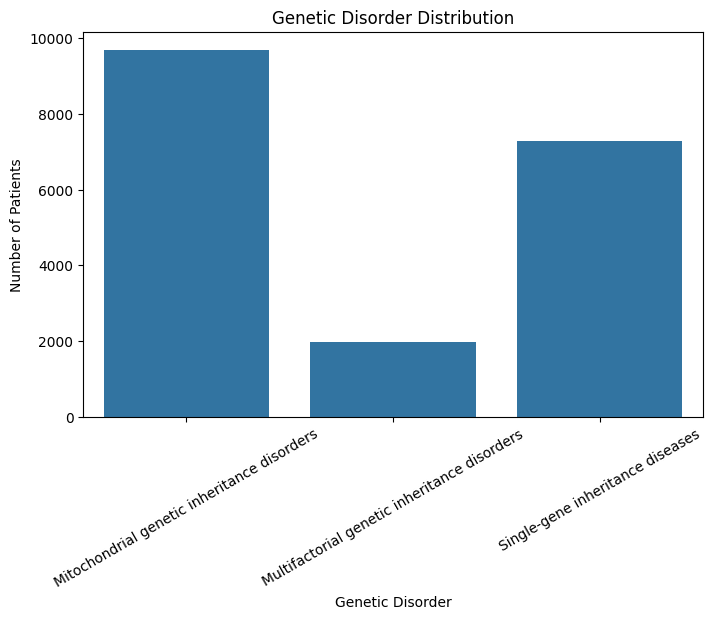

In [11]:

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Genetic Disorder')

plt.title('Genetic Disorder Distribution')
plt.xlabel('Genetic Disorder')
plt.ylabel('Number of Patients')
plt.xticks(rotation=30)

plt.show()


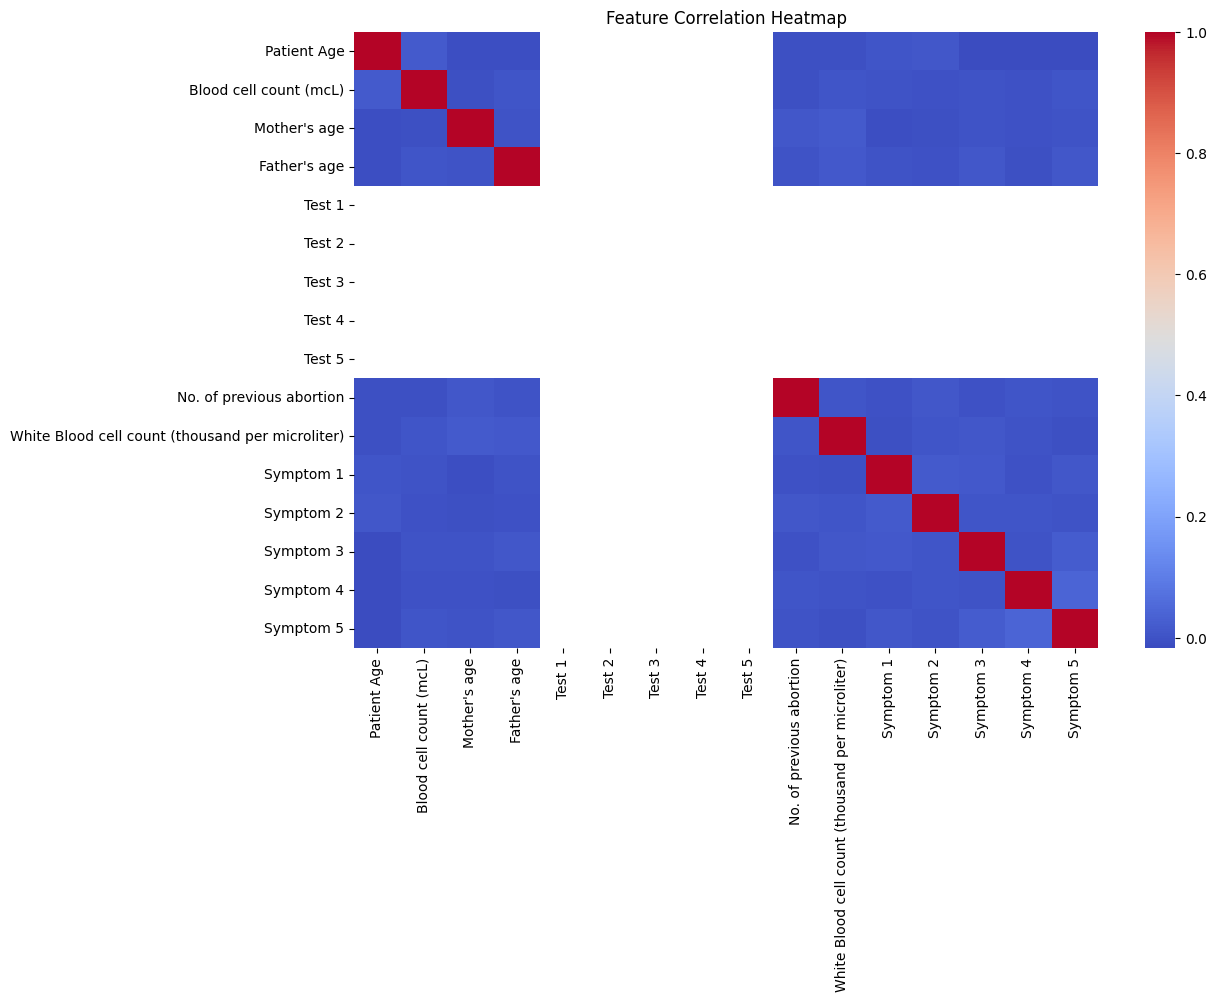

In [12]:

# Correlation between numerical features

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Feature Correlation Heatmap')
plt.show()


In [13]:

# Step 15: Verify Cleaned Dataset

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nRemaining Columns:")
print(df.columns.tolist())

print("\nTarget Values:")
print(df['Genetic Disorder'].value_counts())

print("\nConstant Columns:")
print(df.nunique()[df.nunique() <= 1])


Dataset Shape: (18962, 38)

Missing Values:
0

Remaining Columns:
['Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', "Mother's age", "Father's age", 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5', 'Genetic Disorder']

Target Values:
Genetic Disorder
Mitochondrial genetic inheritance disorders     9686
Single-gene inheritance diseases

In [14]:

# Step 16: Encode Categorical Columns

df_encoded = df.copy()

label_encoders = {}

for col in df_encoded.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le

print("Categorical Encoding Completed!")

display(df_encoded.head())


Categorical Encoding Completed!


,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder
0,2.0,1,0,1,0,4.760603,35.0,42.0,0,0,...,2.0,1,9.857562,3,1.0,1.0,1.0,1.0,1.0,0
2,6.0,1,0,0,0,4.893297,41.0,22.0,0,0,...,4.0,1,7.465056,2,0.0,1.0,1.0,1.0,1.0,1
3,12.0,1,0,1,0,4.705280,21.0,42.0,1,1,...,1.0,1,7.919321,1,0.0,0.0,1.0,0.0,0.0,0
4,11.0,1,0,1,1,4.720703,32.0,42.0,0,1,...,4.0,0,4.098210,3,0.0,0.0,0.0,0.0,0.0,1
5,14.0,1,0,1,0,5.103188,35.0,42.0,1,0,...,0.0,0,10.272230,2,1.0,0.0,0.0,1.0,0.0,2


In [15]:

# Step 17: Separate X and Y

X = df_encoded.drop('Genetic Disorder', axis=1)
y = df_encoded['Genetic Disorder']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (18962, 37)
Target Shape: (18962,)


In [16]:

# Step 18: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (15169, 37)
Testing Data: (3793, 37)


In [17]:

# Step 19: Standardization

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")


Feature Scaling Completed!


In [18]:

# Remove columns having only one unique value

constant_columns = df_encoded.columns[
    df_encoded.nunique() <= 1
].tolist()

df_encoded = df_encoded.drop(columns=constant_columns)

print("Removed Constant Columns:", constant_columns)
print("New Dataset Shape:", df_encoded.shape)


Removed Constant Columns: ['Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent']
New Dataset Shape: (18962, 32)


In [19]:

# Separate Features and Target

X = df_encoded.drop('Genetic Disorder', axis=1)
y = df_encoded['Genetic Disorder']

# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features:", X.shape)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Feature Scaling Completed!")


Features: (18962, 31)
Training Data: (15169, 31)
Testing Data: (3793, 31)
Feature Scaling Completed!


In [20]:

# Step 22: Train Logistic Regression Model

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [21]:

# Step 23: Predict Test Data

y_pred = model.predict(X_test_scaled)

print("Prediction Completed!")

print("\nFirst 10 Predictions:")
print(y_pred[:10])


Prediction Completed!

First 10 Predictions:
[2 1 2 2 1 0 2 0 2 2]


In [22]:

# Step 24: Evaluate Model

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoders['Genetic Disorder'].classes_
))


Model Accuracy: 43.98 %

Classification Report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.65      0.35      0.45      1938
Multifactorial genetic inheritance disorders       0.30      0.86      0.44       397
            Single-gene inheritance diseases       0.40      0.45      0.42      1458

                                    accuracy                           0.44      3793
                                   macro avg       0.45      0.55      0.44      3793
                                weighted avg       0.52      0.44      0.44      3793



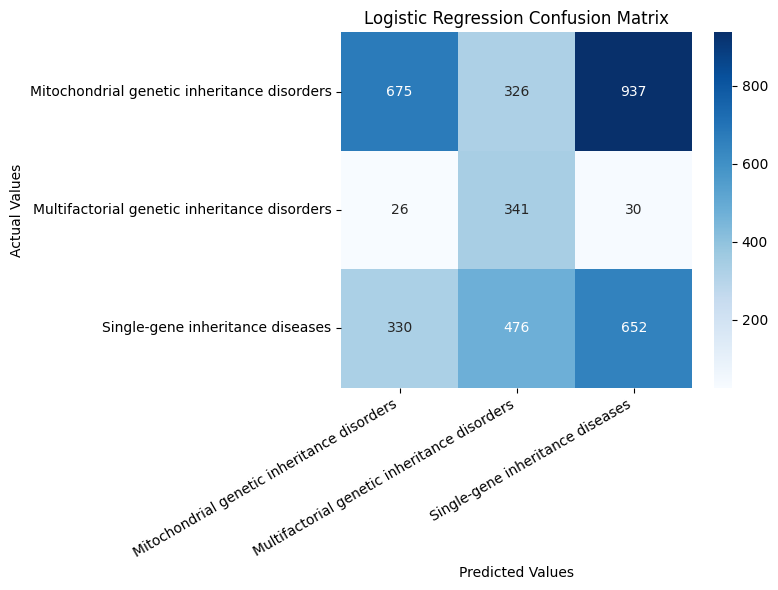

In [23]:

# Step 25: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoders['Genetic Disorder'].classes_,
    yticklabels=label_encoders['Genetic Disorder'].classes_
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()


In [24]:

# Step 26: Cross Validation

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    )
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores)
print("Mean CV Accuracy:", round(cv_scores.mean() * 100, 2), "%")


Cross Validation Scores: [0.43968359 0.44429796 0.43836519 0.46275544 0.46422684]
Mean CV Accuracy: 44.99 %


In [25]:

# Step 27: Prediction Probability

probabilities = model.predict_proba(X_test_scaled)

print("Prediction Probabilities:")
print(probabilities[:5])

print("\nHighest Probability:")
print(round(probabilities[0].max() * 100, 2), "%")


Prediction Probabilities:
[[0.41852711 0.15565762 0.42581527]
 [0.04849318 0.91259743 0.03890938]
 [0.42324953 0.14478157 0.4319689 ]
 [0.44453462 0.09801048 0.4574549 ]
 [0.2017929  0.60302133 0.19518577]]

Highest Probability:
42.58 %


In [26]:

# Step 28: Improved Logistic Regression Model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score

# Use cleaned original dataset
X = df.drop('Genetic Disorder', axis=1)
y = df['Genetic Disorder']

# Remove constant features
X = X.loc[:, X.nunique() > 1]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create two Logistic Regression models
models = {
    'Balanced': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=42
        ))
    ]),

    'Unbalanced': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ])
}

# Compare using 5-fold cross-validation
results = {}

for name, pipe in models.items():
    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring='f1_macro'
    )

    results[name] = scores.mean()

    print(name, "CV Macro F1:",
          round(scores.mean() * 100, 2), "%")

# Select model based on CV Macro F1
best_name = max(results, key=results.get)
model = models[best_name]

# Train selected model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("\nSelected Model:", best_name)
print("Improved Model Training Completed!")


Balanced CV Macro F1: 44.87 %
Unbalanced CV Macro F1: 36.21 %

Selected Model: Balanced
Improved Model Training Completed!


In [27]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

print("Improved Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred))


Improved Model Accuracy: 44.37 %

Classification Report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.65      0.37      0.47      1938
Multifactorial genetic inheritance disorders       0.30      0.85      0.44       397
            Single-gene inheritance diseases       0.40      0.43      0.42      1458

                                    accuracy                           0.44      3793
                                   macro avg       0.45      0.55      0.44      3793
                                weighted avg       0.52      0.44      0.45      3793


Confusion Matrix:
[[716 321 901]
 [ 25 338  34]
 [360 469 629]]


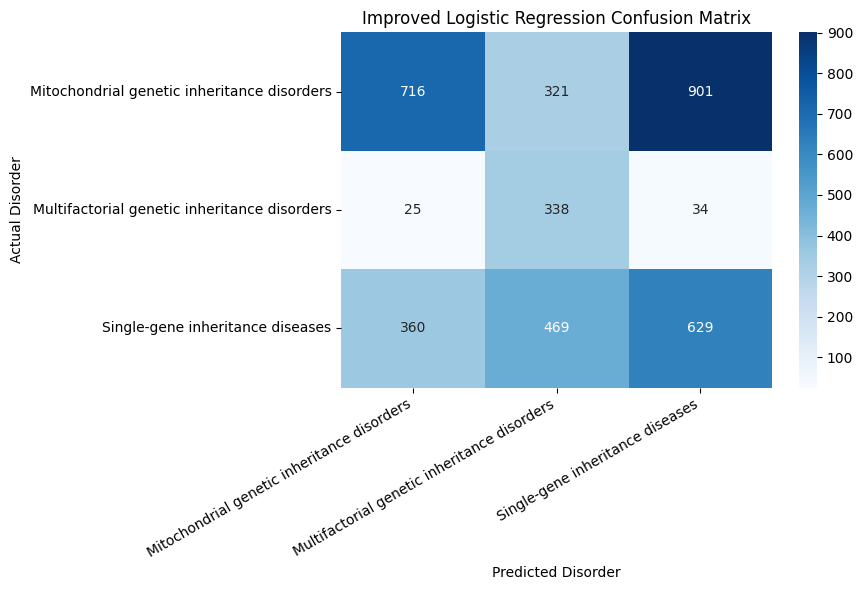

In [28]:

plt.figure(figsize=(9,6))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title('Improved Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Disorder')
plt.ylabel('Actual Disorder')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.show()


In [29]:

import joblib

joblib.dump(model, 'genetic_disorder_model.pkl')

print("Model Saved Successfully!")

files.download('genetic_disorder_model.pkl')


Model Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>